2. Подготовка к работе

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [6]:
df = pd.read_csv("titanic.csv")
print("Размер таблицы:", df.shape)
print(df.head())

Размер таблицы: (891, 12)
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   

3. Формирование таблицы для корреляционного анализа

In [7]:
features = ["Pclass", "Age", "Sex", "Fare", "SibSp", "Parch"]
target = "Survived"

data = df[features + [target]].copy()
print(data.head())

   Pclass   Age     Sex     Fare  SibSp  Parch  Survived
0       3  22.0    male   7.2500      1      0         0
1       1  38.0  female  71.2833      1      0         1
2       3  26.0  female   7.9250      0      0         1
3       1  35.0  female  53.1000      1      0         1
4       3  35.0    male   8.0500      0      0         0


In [8]:
print("Пропуски до обработки:")
print(data.isnull().sum())

Пропуски до обработки:
Pclass        0
Age         177
Sex           0
Fare          0
SibSp         0
Parch         0
Survived      0
dtype: int64


In [9]:
data["Age"] = data["Age"].fillna(data["Age"].median())
print("Пропуски после обработки:")
print(data.isnull().sum())

Пропуски после обработки:
Pclass      0
Age         0
Sex         0
Fare        0
SibSp       0
Parch       0
Survived    0
dtype: int64


In [10]:
data["Sex"] = data["Sex"].map({"male": 0, "female": 1})
print(data.head())

   Pclass   Age  Sex     Fare  SibSp  Parch  Survived
0       3  22.0    0   7.2500      1      0         0
1       1  38.0    1  71.2833      1      0         1
2       3  26.0    1   7.9250      0      0         1
3       1  35.0    1  53.1000      1      0         1
4       3  35.0    0   8.0500      0      0         0


In [11]:
print("Типы данных:")
print(data.dtypes)
print("\nПропуски:")
print(data.isnull().sum())

Типы данных:
Pclass        int64
Age         float64
Sex           int64
Fare        float64
SibSp         int64
Parch         int64
Survived      int64
dtype: object

Пропуски:
Pclass      0
Age         0
Sex         0
Fare        0
SibSp       0
Parch       0
Survived    0
dtype: int64


In [12]:
print("Столбцы таблицы:", list(data.columns))
print("Форма таблицы:", data.shape)
print("\nПервые 5 строк:")
print(data.head())

Столбцы таблицы: ['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch', 'Survived']
Форма таблицы: (891, 7)

Первые 5 строк:
   Pclass   Age  Sex     Fare  SibSp  Parch  Survived
0       3  22.0    0   7.2500      1      0         0
1       1  38.0    1  71.2833      1      0         1
2       3  26.0    1   7.9250      0      0         1
3       1  35.0    1  53.1000      1      0         1
4       3  35.0    0   8.0500      0      0         0


In [13]:
corr = data.corr(numeric_only=True)
print("Корреляционная матрица:")
print(corr.round(2))

Корреляционная матрица:
          Pclass   Age   Sex  Fare  SibSp  Parch  Survived
Pclass      1.00 -0.34 -0.13 -0.55   0.08   0.02     -0.34
Age        -0.34  1.00 -0.08  0.10  -0.23  -0.17     -0.06
Sex        -0.13 -0.08  1.00  0.18   0.11   0.25      0.54
Fare       -0.55  0.10  0.18  1.00   0.16   0.22      0.26
SibSp       0.08 -0.23  0.11  0.16   1.00   0.41     -0.04
Parch       0.02 -0.17  0.25  0.22   0.41   1.00      0.08
Survived   -0.34 -0.06  0.54  0.26  -0.04   0.08      1.00


4. Расчёт корреляционной матрицы

In [14]:
surv_corr = corr["Survived"].drop("Survived")
# Самая сильная положительная
top_pos = surv_corr.idxmax()
print("Наиболее сильная положительная корреляция:",
      f"{top_pos} = {surv_corr[top_pos]:.2f}")
# Самая сильная отрицательная
top_neg = surv_corr.idxmin()
print("Наиболее сильная отрицательная корреляция:",
      f"{top_neg} = {surv_corr[top_neg]:.2f}")

Наиболее сильная положительная корреляция: Sex = 0.54
Наиболее сильная отрицательная корреляция: Pclass = -0.34


5. Построение тепловой карты

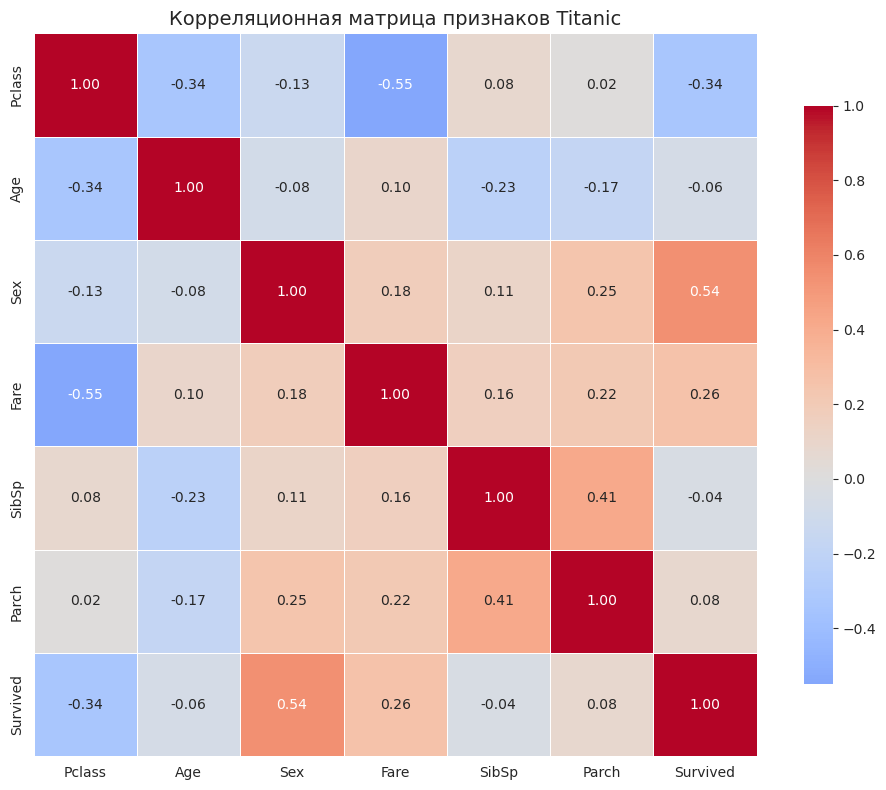

In [15]:
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,        
    fmt=".2f",          
    cmap="coolwarm",     
    center=0,            
    square=True,        
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title("Корреляционная матрица признаков Titanic", fontsize=14)
plt.tight_layout()
plt.show()

 Сравнение корреляционного анализа с задачей машинного обучения
Корреляционный анализ и машинное обучение решают разные задачи, хотя и работают с одними данными.
Корреляционный анализ показывает линейную связь между парами признаков.Он не учитывает, как признаки влияют на целевую переменную совместно. Результат — таблица коэффициентов от −1 до 1.

Какие признаки наиболее полезны для предсказания Survived?
Самые полезные:
Sex (+0.54) — сильнейшая положительная связь. Женщины выживали значительно чаще мужчин. В модели этот признак почти наверняка будет ключевым.
Pclass (−0.34) — сильнейшая отрицательная связь. Чем выше номер класса, тем ниже шанс выжить. Пассажиры первого класса имели приоритет при эвакуации.
Fare (+0.26) — средняя положительная связь. Дороже билет — выше шанс выжить. Логично: дорогие билеты у первого класса. Но этот признак частично дублирует Pclass — они связаны между собой (−0.55)

Можно ли выбирать признаки только по корреляции?
Нет, есть несколько причин.
Первая — корреляция ловит только линейную связь. Если зависимость между признаком и целевой переменной нелинейная, коэффициент Пирсона будет близок к нулю, и признак ошибочно отбросят. Линейная корреляция этого не видит, а дерево решений — видит.
Вторая — корреляция не учитывает взаимодействия. SibSp и Parch по отдельности слабые (−0.04 и +0.08). Но их сумма FamilySize — сильный признак.
Третья — мультиколлинеарность